Autocorrelations: {'lag_1': np.float64(0.9722619109275719), 'lag_48': np.float64(0.9425482362493449), 'lag_336': np.float64(0.878670485762692)}


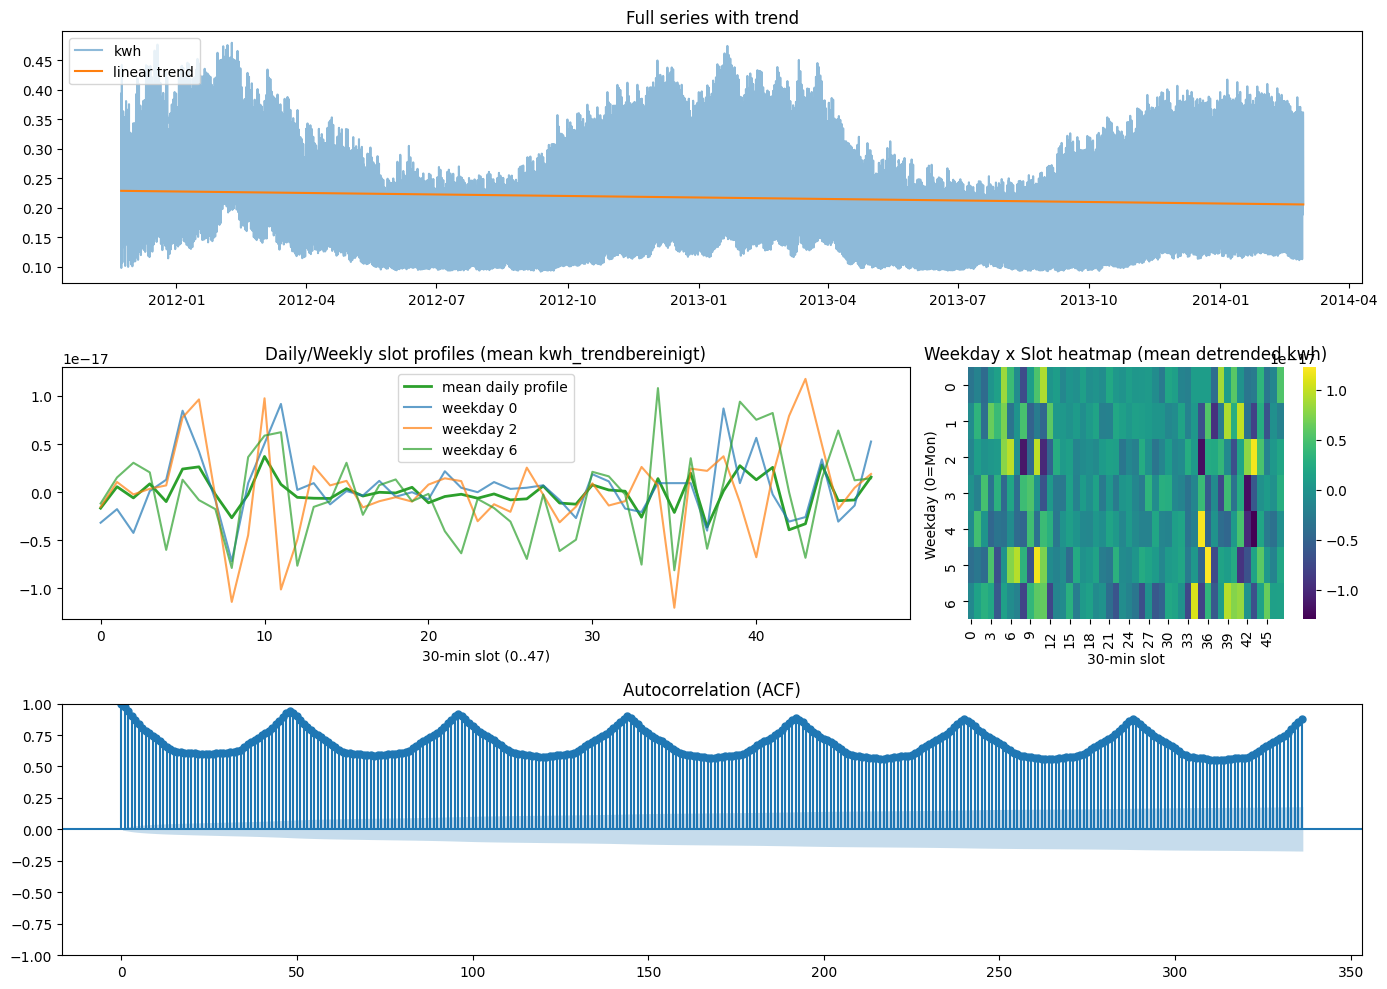

In [39]:
# Improved plots: clearer time series, weekly/daily profiles and heatmap, plus autocorrelation metrics
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.stattools import acf as sm_acf
# optional seaborn styling
try:
    import seaborn as sns
    plt.style.use('seaborn')
except Exception:
    plt.style.use('default')

# Prepare series (prefer weekly-deseasoned if present)
series_name = 'kwh_trendbereinigt_weekly_deseason' if 'kwh_trendbereinigt_weekly_deseason' in df else 'kwh_trendbereinigt'
y = df.get(series_name)
if y is None or y.dropna().empty:
    print(f"{series_name} missing or empty; cannot create improved plots")
else:
    y = y.dropna()
    # basic autocorrelation values at key lags
    acf_lags = { 'lag_1': y.autocorr(lag=1), 'lag_48': y.autocorr(lag=48) if len(y) > 48 else None, 'lag_336': y.autocorr(lag=336) if len(y) > 336 else None }
    print('Autocorrelations:', acf_lags)
    # compute full acf (safe missing='drop') up to seasonal horizon
    max_lag = min(336, int(len(y) / 2))
    acf_vals = sm_acf(y, nlags=max_lag, fft=True, missing='drop')

    # Time-series overview (recent window and long-term)
    fig = plt.figure(figsize=(14, 10))
    gs = fig.add_gridspec(3, 3)
    ax_ts = fig.add_subplot(gs[0:1, :])
    ax_profiles = fig.add_subplot(gs[1, 0:2])
    ax_heat = fig.add_subplot(gs[1, 2])
    ax_acf = fig.add_subplot(gs[2, :])

    # full series + trend overlay if available
    ax_ts.plot(df.index, df.get('kwh', pd.Series(index=df.index, dtype=float)), alpha=0.5, label='kwh')
    if 'kwh_trend' in df:
        ax_ts.plot(df.index, df['kwh_trend'], color='C1', label='linear trend')
    ax_ts.set_title('Full series with trend')
    ax_ts.legend(loc='upper left')

    # weekly/daily profiles: compute slot (0..47) and weekday
    slot = df.index.hour * 2 + (df.index.minute // 30)
    weekday = df.index.dayofweek
    profiles = df.assign(slot=slot, weekday=weekday).groupby(['weekday', 'slot'])[series_name].mean().unstack(level=0)
    # daily mean (mean over weekdays) and weekday-specific mean lines
    mean_daily = profiles.mean(axis=1)
    ax_profiles.plot(mean_daily.index, mean_daily.values, label='mean daily profile', color='C2', linewidth=2)
    # plot a few weekday profiles for contrast (Mon=0, Wed=2, Sun=6 if present)
    for wd in [0,2,6]:
        if wd in profiles.columns:
            ax_profiles.plot(profiles.index, profiles[wd], alpha=0.7, label=f'weekday {wd}')
    ax_profiles.set_xlabel('30-min slot (0..47)')
    ax_profiles.set_title('Daily/Weekly slot profiles (mean kwh_trendbereinigt)')
    ax_profiles.legend()

    # heatmap: weekday vs slot (transpose for nicer orientation)
    try:
        import seaborn as _sns
        heat_data = profiles.T
        heat_data = heat_data.reindex(columns=range(0,48), fill_value=np.nan).reindex(index=range(0,7), fill_value=np.nan)
        _sns.heatmap(heat_data, ax=ax_heat, cmap='viridis', cbar=True)
        ax_heat.set_title('Weekday x Slot heatmap (mean detrended kwh)')
        ax_heat.set_ylabel('Weekday (0=Mon)')
        ax_heat.set_xlabel('30-min slot')
    except Exception:
        heat_data = profiles.T
        ax_heat.imshow(heat_data, aspect='auto', cmap='viridis')
        ax_heat.set_title('Weekday x Slot heatmap (mean detrended kwh)')

    # ACF plot (clearer and larger nlags)
    from statsmodels.graphics.tsaplots import plot_acf
    plot_acf(y, ax=ax_acf, lags=min(336, max_lag))
    ax_acf.set_title('Autocorrelation (ACF)')

    plt.tight_layout()
    plt.show()

In [40]:
# Remove weekly-slot seasonality (focus = weekday*48 + slot) and compare autocorrelations
# This computes a weekly seasonal mean per 30-min slot-of-week and subtracts it from the detrended series
if 'kwh_trendbereinigt' not in df:
    raise RuntimeError('kwh_trendbereinigt missing; run preprocessing first')
slot = df.index.hour * 2 + (df.index.minute // 30)
focus = df.index.dayofweek * 48 + slot
df['focus'] = focus
# weekly slot mean (0..335)
df['kwh_trendbereinigt_saison_weekly'] = df.groupby('focus')['kwh_trendbereinigt'].transform('mean')
# deseasonalized (weekly) series
df['kwh_trendbereinigt_weekly_deseason'] = df['kwh_trendbereinigt'] - df['kwh_trendbereinigt_saison_weekly']
# also keep the simpler daily slot mean for reference
df['kwh_trendbereinigt_daily_mean'] = df.groupby(slot)['kwh_trendbereinigt'].transform('mean')
# quick autocorr diagnostics before/after
y_raw = df['kwh_trendbereinigt'].dropna()
y_week = df['kwh_trendbereinigt_weekly_deseason'].dropna()
print('Autocorr lag 48 (raw) =', y_raw.autocorr(lag=48) if len(y_raw)>48 else None)
print('Autocorr lag 48 (weekly-deseason) =', y_week.autocorr(lag=48) if len(y_week)>48 else None)
print('Autocorr lag 336 (raw) =', y_raw.autocorr(lag=336) if len(y_raw)>336 else None)
print('Autocorr lag 336 (weekly-deseason) =', y_week.autocorr(lag=336) if len(y_week)>336 else None)
# cleanup focus column to match previous notebook behaviour (it was dropped earlier)
df = df.drop(columns=['focus'])

Autocorr lag 48 (raw) = 0.9642011221218271
Autocorr lag 48 (weekly-deseason) = 0.9425482362493449
Autocorr lag 336 (raw) = 0.958784813151914
Autocorr lag 336 (weekly-deseason) = 0.878670485762692


In [31]:
# Try STL-based deseasonalization to remove remaining daily/weekly seasonality
try:
    from statsmodels.tsa.seasonal import STL
except Exception as e:
    print('STL not available in statsmodels:', e)
    print('You can install/upgrade statsmodels (>=0.12) or use the groupby fallback.')
    raise

y = df.get('kwh_trendbereinigt')
if y is None or y.dropna().empty:
    raise RuntimeError('kwh_trendbereinigt missing; run preprocessing first')
y = y.dropna()
print('Original autocorr lag48 =', y.autocorr(lag=48) if len(y)>48 else None)
print('Original autocorr lag336 =', y.autocorr(lag=336) if len(y)>336 else None)

# 1) Remove daily seasonality (period=48) with STL
stl_day = STL(y, period=48, robust=True).fit()
y_no_day = y - stl_day.seasonal
df['kwh_trend_STL_daily_removed'] = y_no_day
print('After STL daily removal: autocorr lag48 =', y_no_day.autocorr(lag=48) if len(y_no_day)>48 else None)
print('After STL daily removal: autocorr lag336 =', y_no_day.autocorr(lag=336) if len(y_no_day)>336 else None)

# 2) Remove weekly seasonality from the daily-cleaned series (period=336)
if len(y_no_day) > 336:
    stl_week = STL(y_no_day, period=336, robust=True).fit()
    y_no_day_week = y_no_day - stl_week.seasonal
    df['kwh_trend_STL_daily_week_removed'] = y_no_day_week
    print('After STL daily+weekly removal: autocorr lag48 =', y_no_day_week.autocorr(lag=48) if len(y_no_day_week)>48 else None)
    print('After STL daily+weekly removal: autocorr lag336 =', y_no_day_week.autocorr(lag=336) if len(y_no_day_week)>336 else None)
else:
    print('Not enough data to run weekly STL (need >336 samples after cleaning)')

# 3) Seasonal differencing fallback: seasonal diff at lag 48 (daily) and 336 (weekly)
y_diff48 = y.diff(48).dropna()
y_diff336 = y.diff(336).dropna()
print('Diff48 length=', len(y_diff48), 'autocorr lag1=', y_diff48.autocorr(lag=1) if len(y_diff48)>1 else None)
print('Diff336 length=', len(y_diff336), 'autocorr lag1=', y_diff336.autocorr(lag=1) if len(y_diff336)>1 else None)

print('Stored STL deseasonalized columns: kwh_trend_STL_daily_removed', 'kwh_trend_STL_daily_week_removed (if available)')

Original autocorr lag48 = 0.9642011221218271
Original autocorr lag336 = 0.958784813151914
After STL daily removal: autocorr lag48 = 0.8813387527757218
After STL daily removal: autocorr lag336 = 0.878757809413827
After STL daily removal: autocorr lag48 = 0.8813387527757218
After STL daily removal: autocorr lag336 = 0.878757809413827
After STL daily+weekly removal: autocorr lag48 = 0.9337721632383011
After STL daily+weekly removal: autocorr lag336 = 0.8666753441591392
Diff48 length= 39679 autocorr lag1= 0.9026213041519728
Diff336 length= 39391 autocorr lag1= 0.9273323391325898
Stored STL deseasonalized columns: kwh_trend_STL_daily_removed kwh_trend_STL_daily_week_removed (if available)
After STL daily+weekly removal: autocorr lag48 = 0.9337721632383011
After STL daily+weekly removal: autocorr lag336 = 0.8666753441591392
Diff48 length= 39679 autocorr lag1= 0.9026213041519728
Diff336 length= 39391 autocorr lag1= 0.9273323391325898
Stored STL deseasonalized columns: kwh_trend_STL_daily_remo

In [36]:
# Try MSTL (multi-seasonal STL) to remove daily+weekly seasonality in one pass
try:
    from statsmodels.tsa.seasonal import MSTL
except Exception as e:
    print('MSTL not available in statsmodels:', e)
    print('Upgrade statsmodels or use STL fallback already computed above')
    raise

y = df.get('kwh_trendbereinigt')
if y is None or y.dropna().empty:
    raise RuntimeError('kwh_trendbereinigt missing; run preprocessing first')
y = y.dropna()
print('Original autocorr lag48 =', y.autocorr(lag=48) if len(y)>48 else None)
print('Original autocorr lag336 =', y.autocorr(lag=336) if len(y)>336 else None)

# MSTL with two seasonal periods: daily=48, weekly=336
mstl = MSTL(y, periods=[48, 336])
res = mstl.fit()
print('MSTL fit completed. Result type =', type(res))
# explore common attribute names to extract seasonal part
seasonal = None
for attr in ('seasonal', 'seasonal_components', 'components', 'seasons', 'seasonal_'):
    if hasattr(res, attr):
        seasonal = getattr(res, attr)
        print('Using MSTL result attribute for seasonal:', attr)
        break

if seasonal is None:
    # sometimes MSTL result exposes a DataFrame via .components or .seasons; try to coerce
    try:
        seasonal = res.result.seasonal
    except Exception:
        pass

if seasonal is None:
    print('Could not extract seasonal component from MSTL result; showing repr(dir(res))')
    print([a for a in dir(res) if not a.startswith('_')])
else:
    # seasonal may be a Series or DataFrame; if DataFrame, sum across seasonal cols
    import pandas as _pd
    if isinstance(seasonal, _pd.DataFrame):
        seasonal_sum = seasonal.sum(axis=1)
    else:
        seasonal_sum = seasonal
    # align with y's index and subtract
    seasonal_sum = seasonal_sum.reindex(y.index)
    y_mstl_deseason = y - seasonal_sum
    df['kwh_trend_mstl_deseason'] = y_mstl_deseason
    print('After MSTL deseason: autocorr lag48 =', y_mstl_deseason.autocorr(lag=48) if len(y_mstl_deseason)>48 else None)
    print('After MSTL deseason: autocorr lag336 =', y_mstl_deseason.autocorr(lag=336) if len(y_mstl_deseason)>336 else None)
    print('Stored MSTL-deseasoned series in df[kwh_trend_mstl_deseason]')
    # Additional deseasonalization attempts: Ridge on slot-of-week dummies and Fourier-term regression
    # 1) Ridge on focus dummies (fallback to groupby already exists if sklearn is not available)
    try:
        import numpy as _np
        import pandas as _pd
        from sklearn.linear_model import Ridge
        print('sklearn Ridge available; fitting Ridge on slot-of-week dummies')
        focus = y.index.dayofweek * 48 + (y.index.hour * 2 + (y.index.minute // 30))
        X_focus = _pd.get_dummies(focus).astype(float)
        model = Ridge(alpha=1.0, fit_intercept=True)
        model.fit(X_focus.values, y.values)
        seasonal_pred = _pd.Series(model.predict(X_focus.values), index=y.index)
        df['kwh_trend_ridge_focus_deseason'] = y - seasonal_pred
        print('Ridge-focus deseason: autocorr lag48 =', df['kwh_trend_ridge_focus_deseason'].autocorr(lag=48) if len(y)>48 else None)
        print('Ridge-focus deseason: autocorr lag336 =', df['kwh_trend_ridge_focus_deseason'].autocorr(lag=336) if len(y)>336 else None)
    except Exception as _e:
        print('Ridge-focus approach unavailable or failed:', _e)

    # 2) Fourier terms (daily + weekly harmonics) with Ridge regularization
    try:
        import numpy as _np
        import pandas as _pd
        from sklearn.linear_model import Ridge
        t = _np.arange(len(y))
        def fourier_terms(t, period, n_harmonics):
            cols = []
            for k in range(1, n_harmonics+1):
                cols.append(_np.sin(2*_np.pi*k*t/period))
                cols.append(_np.cos(2*_np.pi*k*t/period))
            return _np.column_stack(cols) if cols else _np.empty((len(t),0))
        Xd = fourier_terms(t, 48, 6)  # daily harmonics
        Xw = fourier_terms(t, 336, 3) # weekly harmonics
        if Xd.size and Xw.size:
            X = _np.hstack([Xd, Xw])
        else:
            X = Xd if Xw.size==0 else Xw
        model = Ridge(alpha=1.0)
        model.fit(X, y.values)
        seasonal_pred = _pd.Series(model.predict(X), index=y.index)
        df['kwh_trend_fourier_deseason'] = y - seasonal_pred
        print('Fourier deseason: autocorr lag48 =', df['kwh_trend_fourier_deseason'].autocorr(lag=48) if len(y)>48 else None)
        print('Fourier deseason: autocorr lag336 =', df['kwh_trend_fourier_deseason'].autocorr(lag=336) if len(y)>336 else None)
    except Exception as _e:
        print('Fourier approach unavailable or failed:', _e)

Original autocorr lag48 = 0.9642011221218271
Original autocorr lag336 = 0.958784813151914
MSTL fit completed. Result type = <class 'statsmodels.tsa.seasonal.DecomposeResult'>
Using MSTL result attribute for seasonal: seasonal
After MSTL deseason: autocorr lag48 = 0.9438081213522518
After MSTL deseason: autocorr lag336 = 0.8760613720239585
Stored MSTL-deseasoned series in df[kwh_trend_mstl_deseason]
MSTL fit completed. Result type = <class 'statsmodels.tsa.seasonal.DecomposeResult'>
Using MSTL result attribute for seasonal: seasonal
After MSTL deseason: autocorr lag48 = 0.9438081213522518
After MSTL deseason: autocorr lag336 = 0.8760613720239585
Stored MSTL-deseasoned series in df[kwh_trend_mstl_deseason]
sklearn Ridge available; fitting Ridge on slot-of-week dummies
sklearn Ridge available; fitting Ridge on slot-of-week dummies
Ridge-focus deseason: autocorr lag48 = 0.9425529132283905
Ridge-focus deseason: autocorr lag336 = 0.8786862622324535
Fourier deseason: autocorr lag48 = 0.909745

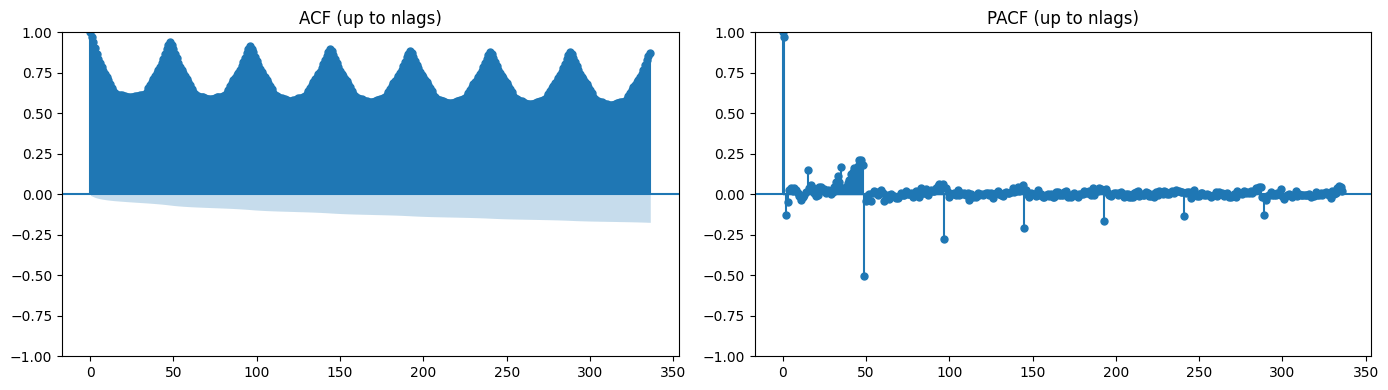

In [42]:
# Enhanced ACF/PACF with wider lags and nice labels
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# prefer the deseasoned weekly series when available
series_name = 'kwh_trendbereinigt_weekly_deseason' if 'kwh_trendbereinigt_weekly_deseason' in df else 'kwh_trendbereinigt'
y = df.get(series_name)
if y is None or y.dropna().empty:
    print(f"{series_name} missing or empty; cannot plot ACF/PACF")
else:
    y = y.dropna()
    nlags = min(336, int(len(y)/2))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(y, lags=nlags, ax=axes[0], alpha=0.05)
    plot_pacf(y, lags=nlags, ax=axes[1], method='ywm')
    axes[0].set_title('ACF (up to nlags)')
    axes[1].set_title('PACF (up to nlags)')
    plt.tight_layout()
    plt.show()

In [43]:
# Supervised ML seasonal prediction (LightGBM if available, else RandomForest)
# Produces out-of-fold predictions for the seasonal component and a deseasoned series
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

if 'kwh_trendbereinigt' not in df:
    raise RuntimeError('kwh_trendbereinigt missing; run preprocessing first')
y = df['kwh_trendbereinigt'].dropna()
if len(y) < 100:
    print('Insufficient data for ML seasonal model (<100 samples)')
else:
    # features: slot, weekday, hour, month, slot_week, cyclical transforms, trend index
    X = pd.DataFrame(index=y.index)
    X['slot'] = y.index.hour * 2 + (y.index.minute // 30)
    X['weekday'] = y.index.dayofweek
    X['hour'] = y.index.hour
    X['month'] = y.index.month
    try:
        X['weekofyear'] = y.index.isocalendar().week.values
    except Exception:
        X['weekofyear'] = y.index.week
    X['slot_week'] = y.index.dayofweek * 48 + X['slot']
    t = np.arange(len(y))
    X['t'] = t
    # cyclical encodings
    X['slot_sin'] = np.sin(2 * np.pi * X['slot'] / 48)
    X['slot_cos'] = np.cos(2 * np.pi * X['slot'] / 48)
    X['dow_sin'] = np.sin(2 * np.pi * X['weekday'] / 7)
    X['dow_cos'] = np.cos(2 * np.pi * X['weekday'] / 7)
    # small rolling features (avoid lookahead) computed on y
    X['y_roll7'] = y.rolling(window=7, min_periods=1).mean().values

    # choose model class: LightGBM if available, else RandomForest as fallback
    try:
        import lightgbm as lgb
        Model = lgb.LGBMRegressor
        model_kwargs = dict(n_estimators=200, random_state=0)
        print('Using LightGBM for seasonal prediction')
    except Exception:
        from sklearn.ensemble import RandomForestRegressor
        Model = RandomForestRegressor
        model_kwargs = dict(n_estimators=100, random_state=0, n_jobs=-1)
        print('LightGBM not available; using RandomForest fallback')

    # out-of-fold predictions to avoid leakage
    n_splits = 5 if len(y) >= 200 else 3
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=0)
    oof = np.zeros(len(y), dtype=float)
    for train_idx, val_idx in kf.split(X):
        model = Model(**model_kwargs)
        model.fit(X.iloc[train_idx], y.values[train_idx])
        oof[val_idx] = model.predict(X.iloc[val_idx])
    seasonal_pred = pd.Series(oof, index=y.index)
    df['kwh_trend_ml_seasonal'] = seasonal_pred.reindex(df.index)
    df['kwh_trend_ml_deseason'] = df['kwh_trendbereinigt'] - df['kwh_trend_ml_seasonal']
    print('ML seasonal deseason: autocorr lag48 =', df['kwh_trend_ml_deseason'].autocorr(lag=48) if len(y)>48 else None)
    print('ML seasonal deseason: autocorr lag336 =', df['kwh_trend_ml_deseason'].autocorr(lag=336) if len(y)>336 else None)
    # keep oof predictions for inspection
    df['kwh_trend_ml_seasonal_oof'] = df['kwh_trend_ml_seasonal']
    print('Stored ML seasonal predictions in df[kwh_trend_ml_seasonal] and deseasoned in df[kwh_trend_ml_deseason]')

LightGBM not available; using RandomForest fallback
ML seasonal deseason: autocorr lag48 = 0.14678509603067186
ML seasonal deseason: autocorr lag336 = 0.09063913611224245
Stored ML seasonal predictions in df[kwh_trend_ml_seasonal] and deseasoned in df[kwh_trend_ml_deseason]
ML seasonal deseason: autocorr lag48 = 0.14678509603067186
ML seasonal deseason: autocorr lag336 = 0.09063913611224245
Stored ML seasonal predictions in df[kwh_trend_ml_seasonal] and deseasoned in df[kwh_trend_ml_deseason]


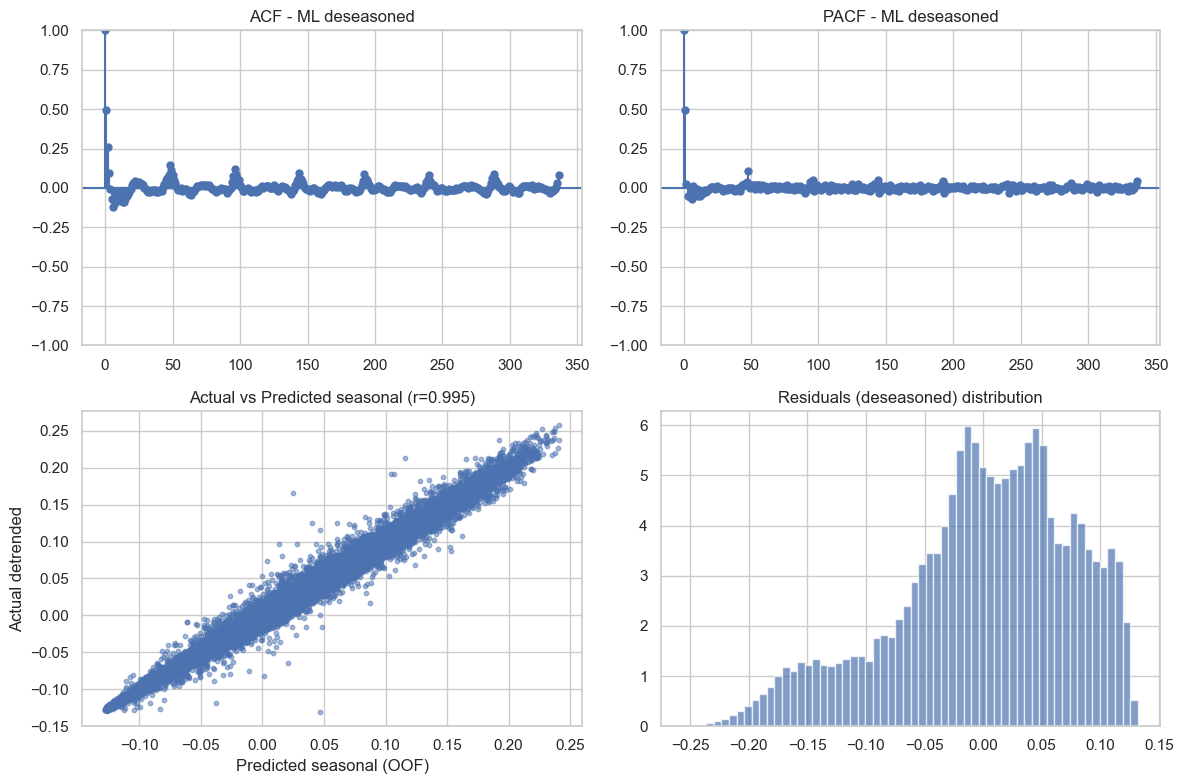

ML-deseason autocorr lag1 = 0.49473215534175236
ML-deseason autocorr lag48 = 0.14678509603067186
ML-deseason autocorr lag336 = 0.09063913611224245


In [44]:
# Diagnostics and correlation plots for the ML seasonal solution
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# optional seaborn styling
try:
    import seaborn as sns
    sns.set(style='whitegrid')
except Exception:
    pass
# prefer the ML deseasoned series if present
if 'kwh_trend_ml_deseason' not in df or df['kwh_trend_ml_deseason'].dropna().empty:
    print('ML deseasoned series not found or empty; run the ML cell first')
else:
    y_ml = df['kwh_trend_ml_deseason'].dropna()
    # ACF/PACF for the deseasoned series
    nlags = min(336, int(len(y_ml)/2))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    plot_acf(y_ml, lags=nlags, ax=axes[0,0], alpha=0.05)
    axes[0,0].set_title('ACF - ML deseasoned')
    plot_pacf(y_ml, lags=nlags, ax=axes[0,1], method='ywm')
    axes[0,1].set_title('PACF - ML deseasoned')
    # scatter actual detrended vs predicted seasonal (OOF)
    if 'kwh_trend_ml_seasonal_oof' in df and not df['kwh_trend_ml_seasonal_oof'].dropna().empty:
        pred = df['kwh_trend_ml_seasonal_oof'].reindex(y_ml.index).dropna()
        # align with original detrended observations that correspond to predictions
        common_idx = y_ml.index.intersection(pred.index)
        if len(common_idx) > 0:
            actual_det = df.loc[common_idx, 'kwh_trendbereinigt']
            pred_seas = pred.loc[common_idx]
            corr, p = pearsonr(actual_det.values, pred_seas.values)
            axes[1,0].scatter(pred_seas.values, actual_det.values, alpha=0.5, s=10)
            axes[1,0].set_xlabel('Predicted seasonal (OOF)')
            axes[1,0].set_ylabel('Actual detrended')
            axes[1,0].set_title(f'Actual vs Predicted seasonal (r={corr:.3f})')
        else:
            axes[1,0].text(0.5,0.5,'No overlapping predictions', ha='center')
    else:
        axes[1,0].text(0.5,0.5,'No OOF predictions available', ha='center')
    # histogram / density of residuals
    resid = y_ml - (df['kwh_trend_ml_seasonal_oof'].reindex(y_ml.index) if 'kwh_trend_ml_seasonal_oof' in df else 0)
    axes[1,1].hist(resid.dropna().values, bins=60, density=True, alpha=0.7)
    axes[1,1].set_title('Residuals (deseasoned) distribution')
    plt.tight_layout()
    plt.show()
    # print key autocorrelations
    print('ML-deseason autocorr lag1 =', y_ml.autocorr(lag=1) if len(y_ml)>1 else None)
    print('ML-deseason autocorr lag48 =', y_ml.autocorr(lag=48) if len(y_ml)>48 else None)
    print('ML-deseason autocorr lag336 =', y_ml.autocorr(lag=336) if len(y_ml)>336 else None)